<a href="https://colab.research.google.com/github/BrunoCapron/AprendizadoPorRefor-o/blob/main/casos/actor_critic_cstr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actor-critic modernos na prática: SAC, TD3, DDPG e PPO em um CSTR

**Objetivo:** treinar os quatro algoritmos no controle de concentração de um reator CSTR exotérmico e compará-los com um controlador PI.

Roteiro:
1. Ambiente (CSTR do Seborg) como `gymnasium.Env`
2. Baseline: controlador PI
3. Treinamento com Stable-Baselines3
4. Curvas de aprendizado, respostas ao degrau e métricas

> Dica: em *Ambiente de execução → Alterar tipo*, CPU basta. Com `TOTAL_STEPS = 30_000` o treino completo leva alguns minutos; aumente para resultados melhores.

In [1]:
!pip -q install gymnasium stable-baselines3 matplotlib pandas

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import SAC, TD3, DDPG, PPO
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.noise import NormalActionNoise

SEED = 0
np.random.seed(SEED)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 1. O ambiente: CSTR exotérmico

Reação de primeira ordem A → B em um reator de mistura perfeita com camisa de resfriamento:

$$\frac{dC_A}{dt}=\frac{q}{V}(C_{A,f}-C_A)-k_0 e^{-E/RT}C_A$$
$$\frac{dT}{dt}=\frac{q}{V}(T_f-T)+\frac{-\Delta H}{\rho C_p}k_0 e^{-E/RT}C_A+\frac{UA}{V\rho C_p}(T_c-T)$$

- **Ação:** temperatura da camisa $T_c$ (a ação $a\in[-1,1]$ é reescalada para 290–305 K).
- **Observação:** $[C_A,\ T_{norm},\ C_{A,sp},\ 5(C_{A,sp}-C_A)]$.
- **Recompensa:** $-10\,e^2-0{,}05\,(\Delta a)^2$, com penalidade de $-50$ e término do episódio se houver disparo térmico ($T>400$ K).
- **Episódio:** 120 passos de 0,5 min; o setpoint de $C_A$ muda a cada 40 passos (sorteado em [0,75; 0,90]).

O processo é fortemente não linear e tem múltiplos estados estacionários, o que o torna um bom teste para RL.

In [4]:
class CSTREnv(gym.Env):
    """CSTR exotérmico A->B (Seborg). Ação: temperatura do fluido de resfriamento Tc. Controlado: Ca."""
    P = dict(q=100., V=100., Caf=1., Tf=350., rhoCp=239., dH=-5e4, EoR=8750., k0=7.2e10, UA=5e4)

    def __init__(self, dt=0.5, n_steps=120, seg=40, sp_range=(0.75, 0.9), meas_noise=0.0, seed=None):
        super().__init__()
        self.dt, self.n_steps, self.seg, self.sp_range, self.meas_noise = dt, n_steps, seg, sp_range, meas_noise
        self.action_space = spaces.Box(-1.0, 1.0, shape=(1,), dtype=np.float32)
        self.observation_space = spaces.Box(-10.0, 10.0, shape=(4,), dtype=np.float32)
        self.fixed_sp = None
        self.reset(seed=seed)

    @staticmethod
    def a2Tc(a):  # [-1,1] -> [290,305] K
        return 297.5 + 7.5 * float(np.clip(a, -1, 1))

    def _f(self, x, Tc):
        p = self.P
        Ca, T = x[0], np.clip(x[1], 250., 420.)
        k = p['k0'] * np.exp(-p['EoR'] / T)
        dCa = p['q'] / p['V'] * (p['Caf'] - Ca) - k * Ca
        dT = (p['q'] / p['V'] * (p['Tf'] - T) - p['dH'] / p['rhoCp'] * k * Ca
              + p['UA'] / (p['V'] * p['rhoCp']) * (Tc - T))
        return np.array([dCa, dT])

    def _integrate(self, x, Tc, n=40):
        h = self.dt / n
        for _ in range(n):
            k1 = self._f(x, Tc); k2 = self._f(x + h/2*k1, Tc)
            k3 = self._f(x + h/2*k2, Tc); k4 = self._f(x + h*k3, Tc)
            x = x + h/6*(k1 + 2*k2 + 2*k3 + k4)
        return x

    def _sp(self):
        return self.sps[min(self.t // self.seg, len(self.sps) - 1)]

    def _obs(self):
        Ca = self.x[0] + self.meas_noise * self.np_random.standard_normal()
        T = self.x[1] + 10 * self.meas_noise * self.np_random.standard_normal()
        sp = self._sp()
        return np.array([Ca, (T - 330.) / 20., sp, 5 * (sp - Ca)], dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.x = np.array([0.8773, 324.475])           # estado estacionário estável com Tc = 300 K
        self.t, self.last_a = 0, 0.0
        n_seg = int(np.ceil(self.n_steps / self.seg))
        self.sps = self.fixed_sp if self.fixed_sp is not None else \
            self.np_random.uniform(*self.sp_range, size=n_seg)
        return self._obs(), {}

    def step(self, action):
        a = float(np.clip(action, -1, 1).reshape(-1)[0])
        self.x = self._integrate(self.x, self.a2Tc(a))
        self.t += 1
        e = self._sp() - self.x[0]
        reward = -10.0 * e**2 - 0.05 * (a - self.last_a)**2
        self.last_a = a
        terminated = bool(self.x[1] > 400. or self.x[0] < 0.0)   # disparo térmico (runaway)
        if terminated:
            reward -= 50.0
        truncated = self.t >= self.n_steps
        return self._obs(), reward, terminated, truncated, {"Ca": self.x[0], "T": self.x[1], "Tc": self.a2Tc(a), "sp": self._sp()}

## 2. Baseline: controlador PI com anti-windup

Ação direta: se $C_A$ está acima do setpoint, aumenta-se $T_c$ (mais reação, menos reagente). O PI foi ajustado manualmente ($K_c=20$ K/(mol/L), $\tau_I=8$ min).

In [5]:
class PIController:
    def __init__(self, Kc=20., Ti=8., dt=0.5):
        self.Kc, self.Ti, self.dt = Kc, Ti, dt
        self.reset()
    def reset(self):
        self.I = 0.
    def __call__(self, obs):
        e = obs[2] - obs[0]                       # sp - Ca
        Tc = 300. - self.Kc * e - self.Kc / self.Ti * self.I
        Tc_sat = np.clip(Tc, 290., 305.)
        if Tc == Tc_sat:                          # anti-windup por clamping
            self.I += e * self.dt
        return np.array([(Tc_sat - 297.5) / 7.5], dtype=np.float32)

def evaluate(policy, sps_list, seed=123):
    """Roda a política em cada perfil de setpoint e devolve trajetórias e métricas."""
    runs = []
    for i, sps in enumerate(sps_list):
        env = CSTREnv(); env.fixed_sp = np.array(sps)
        obs, _ = env.reset(seed=seed + i)
        if hasattr(policy, "reset"): policy.reset()
        Ca, sp, Tc, R, runaway = [], [], [], 0., False
        for _ in range(env.n_steps):
            obs, r, term, trunc, info = env.step(policy(obs))
            R += r; Ca.append(info["Ca"]); sp.append(info["sp"]); Tc.append(info["Tc"])
            if term: runaway = True; break
            if trunc: break
        Ca, sp, Tc = map(np.array, (Ca, sp, Tc))
        runs.append(dict(Ca=Ca, sp=sp, Tc=Tc, ret=R, iae=np.abs(Ca - sp).mean(),
                         effort=np.abs(np.diff(Tc)).mean() if len(Tc) > 1 else 0., runaway=runaway))
    return runs

rng = np.random.default_rng(123)
TEST_SPS = rng.uniform(0.75, 0.90, size=(20, 3))      # 20 perfis de teste
DEMO_SP = [[0.88, 0.78, 0.85]]                        # perfil usado nos gráficos

def summarize(runs):
    return dict(retorno=np.mean([r["ret"] for r in runs]),
                IAE=np.mean([r["iae"] for r in runs]),
                esforço=np.mean([r["effort"] for r in runs]),
                disparos=int(sum(r["runaway"] for r in runs)))

pi_runs = evaluate(PIController(), TEST_SPS)
print("PI:", summarize(pi_runs))

PI: {'retorno': np.float64(-0.9732511911094658), 'IAE': np.float64(0.021642727130873434), 'esforço': np.float64(0.036895497349881325), 'disparos': 0}


## 3. Treinamento

Os quatro algoritmos usam o mesmo ambiente e o mesmo orçamento de passos. Pontos de atenção:

- **DDPG/TD3** usam ruído de exploração gaussiano (`NormalActionNoise`).
- **SAC** explora pela entropia, com α automático.
- **PPO** é on-policy: costuma precisar de mais passos que os off-policy.

In [6]:
TOTAL_STEPS = 30_000     # aumente (ex.: 100_000) para resultados melhores
noise = lambda: NormalActionNoise(mean=np.zeros(1), sigma=0.1 * np.ones(1))

def make_agent(name, env):
    kw = dict(policy="MlpPolicy", env=env, seed=SEED, verbose=0)
    if name == "SAC":  return SAC(learning_starts=1000, **kw)
    if name == "TD3":  return TD3(learning_starts=1000, action_noise=noise(), **kw)
    if name == "DDPG": return DDPG(learning_starts=1000, action_noise=noise(), **kw)
    if name == "PPO":  return PPO(n_steps=1024, batch_size=64, **kw)

agents, curves = {}, {}
for name in ["SAC", "TD3", "DDPG", "PPO"]:
    env = Monitor(CSTREnv())
    model = make_agent(name, env)
    model.learn(total_timesteps=TOTAL_STEPS)
    agents[name], curves[name] = model, env.get_episode_rewards()
    print(f"{name}: {len(curves[name])} episódios, retorno médio dos últimos 10 = {np.mean(curves[name][-10:]):.1f}")

SAC: 250 episódios, retorno médio dos últimos 10 = -0.8


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


TD3: 253 episódios, retorno médio dos últimos 10 = -0.9
DDPG: 252 episódios, retorno médio dos últimos 10 = -0.7
PPO: 273 episódios, retorno médio dos últimos 10 = -17.0


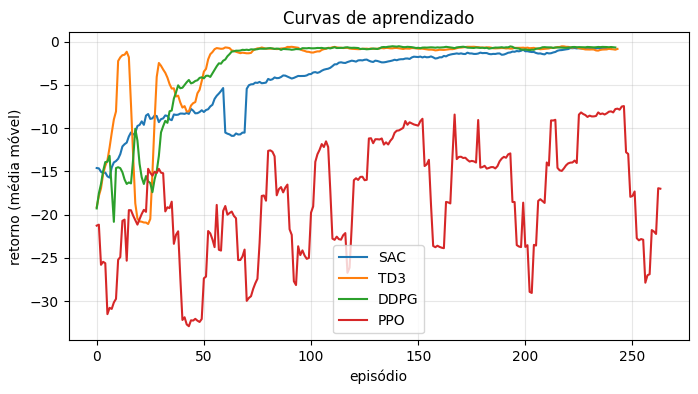

In [7]:
def smooth(x, w=10):
    x = np.asarray(x); w = min(w, len(x))
    return np.convolve(x, np.ones(w) / w, mode="valid")

plt.figure(figsize=(8, 4))
for name, ep in curves.items():
    plt.plot(smooth(ep), label=name)
plt.xlabel("episódio"); plt.ylabel("retorno (média móvel)"); plt.title("Curvas de aprendizado")
plt.legend(); plt.grid(alpha=.3); plt.show()

## 4. Avaliação

Política determinística (`deterministic=True`) em 20 perfis de setpoint não vistos no treinamento.

In [8]:
policies = {"PI": PIController()}
for name, m in agents.items():
    policies[name] = (lambda model: (lambda obs: model.predict(obs, deterministic=True)[0]))(m)

results = {n: evaluate(p, TEST_SPS) for n, p in policies.items()}
table = pd.DataFrame({n: summarize(r) for n, r in results.items()}).T
table.round(3)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,retorno,IAE,esforço,disparos
PI,-0.973,0.022,0.037,0.0
SAC,-0.814,0.021,0.190,0.0
TD3,-0.378,0.011,0.246,0.0
DDPG,-0.408,0.012,0.146,0.0
PPO,-1.578,0.030,0.168,0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2020: PyparsingDeprecationWarning: 'leaveWhitespace' deprecated - use 'leave_whitespace'
  )("sym").leaveWhitespace()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:1984: PyparsingDeprecationWarning: 'setName' deprecated - use 'set_name'
  val.setName(key)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:1987: PyparsingDeprecationWarning: 'setParseA

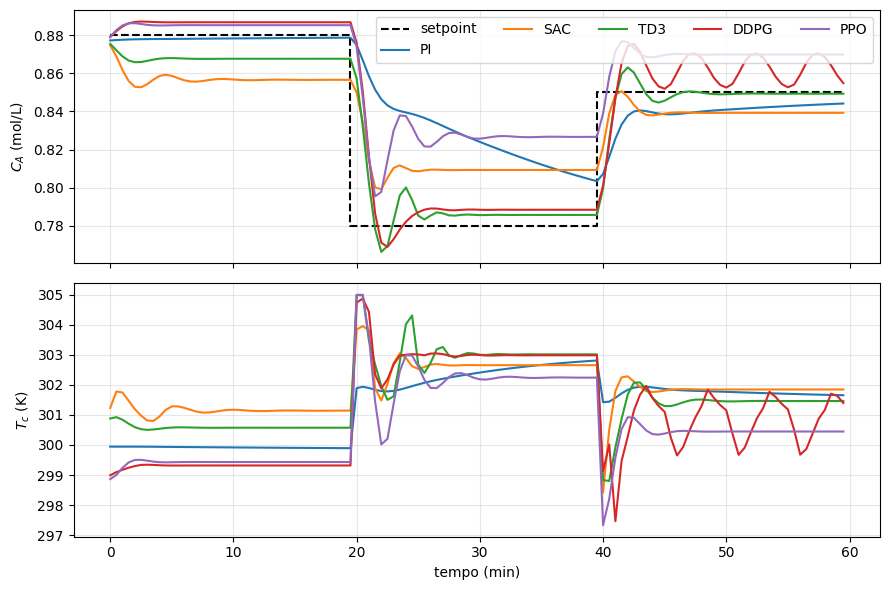

In [9]:
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
demo = {n: evaluate(p, DEMO_SP)[0] for n, p in policies.items()}
t = np.arange(len(next(iter(demo.values()))["sp"])) * 0.5
ax[0].step(t, demo["PI"]["sp"], "k--", where="post", label="setpoint")
for n, r in demo.items():
    ax[0].plot(np.arange(len(r["Ca"])) * 0.5, r["Ca"], label=n)
    ax[1].plot(np.arange(len(r["Tc"])) * 0.5, r["Tc"], label=n)
ax[0].set_ylabel("$C_A$ (mol/L)"); ax[1].set_ylabel("$T_c$ (K)"); ax[1].set_xlabel("tempo (min)")
ax[0].legend(ncol=5); ax[0].grid(alpha=.3); ax[1].grid(alpha=.3); plt.tight_layout(); plt.show()

## 5. Para o trabalho final

Sugestões de extensão (escolha uma e use **um** dos algoritmos):

1. **Reward shaping:** altere os pesos do erro e do esforço de controle e observe o efeito sobre o comportamento (oscilação, offset).
2. **Robustez:** ative `meas_noise` (por exemplo, 0,01) e/ou perturbe parâmetros do processo (`UA`, `Caf`) no `reset`.
3. **Faixa de setpoints:** estenda `sp_range` para a região instável (C_A < 0,75). O PI deixa de funcionar bem, e o RL pode ou não aprender. Discuta por quê.
4. **Várias sementes:** repita o treino com 3 a 5 sementes e reporte média e dispersão.
5. **Hiperparâmetros:** varie a taxa de aprendizado, o tamanho do lote e o `TOTAL_STEPS`.
6. **Outro processo:** troque o CSTR por outro ambiente (coluna, reator em batelada).

Perguntas: por que o PPO precisa de mais passos? O que o ruído de exploração faz no DDPG/TD3 que o SAC faz de outro jeito? Em que situações o PI ainda seria preferível?